# 03 — Customer Behavior EDA

## Reproducibility and setup
The first code cell locates the project folder from the current directory or the configured Windows path.
The datasets are synthetic teaching data generated with a fixed random seed. Findings are practice examples, not claims about a real business.

Questions: Which customer characteristics associate with conversion? Are there segments? Which values need validation?

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents, Path(r"E:\Linkific\Day 7")):
    if (candidate / "src" / "__init__.py").is_file() and (candidate / "data" / "raw").is_dir():
        PROJECT_ROOT = candidate.resolve()
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from E:\\Linkific\\Day 7 "
        "or update the fallback path in this cell."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "customer_behavior.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src.data_quality import quality_summary, numeric_outlier_summary
from src.statistical_analysis import describe_numeric, mann_whitney_test
from src.profiling import create_profile

sns.set_theme()
df = pd.read_csv(DATA_PATH)
df.head()

,customer_id,age,sessions_last_30d,avg_order_value,days_since_last_purchase,support_tickets,device,acquisition_channel,converted
0,C00001,20.0,3,85.36,65,0,Mobile,Paid Search,1
1,C00002,59.0,9,106.24,53,2,Desktop,Organic,1
2,C00003,67.0,12,34.23,56,1,Tablet,Organic,0
3,C00004,27.0,10,92.59,153,0,Tablet,Organic,0
4,C00005,36.0,3,99.73,116,1,Desktop,Social,0


## 1. Data types and quality

In [2]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype"))
display(quality_summary(df))
display(numeric_outlier_summary(df))
print("Conversion values:", df["converted"].value_counts(dropna=False).to_dict())
print("Conversion rate:", round(df["converted"].mean()*100, 2), "%")

Shape: (1500, 9)


,dtype
customer_id,object
age,float64
sessions_last_30d,int64
avg_order_value,float64
days_since_last_purchase,int64
support_tickets,int64
device,object
acquisition_channel,object
converted,int64


,column,dtype,missing_count,missing_pct,unique_count,duplicate_rows_total
0,customer_id,object,0,0.00,1500,0
1,age,float64,4,0.27,58,0
2,sessions_last_30d,int64,0,0.00,19,0
3,avg_order_value,float64,0,0.00,1365,0
4,days_since_last_purchase,int64,0,0.00,180,0
5,support_tickets,int64,0,0.00,7,0
6,device,object,0,0.00,3,0
7,acquisition_channel,object,0,0.00,5,0
8,converted,int64,0,0.00,2,0


,column,q1,q3,iqr,lower_fence,upper_fence,potential_outliers
0,age,32.000,60.0000,28.0000,-10.00000,102.00000,0
1,sessions_last_30d,6.000,10.0000,4.0000,0.00000,16.00000,3
2,avg_order_value,57.835,92.1325,34.2975,6.38875,143.57875,5
3,days_since_last_purchase,44.000,133.2500,89.2500,-89.87500,267.12500,0
4,support_tickets,0.000,2.0000,2.0000,-3.00000,5.00000,3
5,converted,0.000,0.0000,0.0000,0.00000,0.00000,302


Conversion values: {0: 1198, 1: 302}
Conversion rate: 20.13 %


## 2. Numerical distributions

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,variance,skewness,kurtosis_excess
age,1496.0,46.175802,16.725779,18.0,18.0000,20.000,32.000,46.000,60.0000,73.0000,75.0000,75.0,279.751682,0.021417,-1.174208
sessions_last_30d,1500.0,8.044000,2.807487,0.0,2.0000,4.000,6.000,8.000,10.0000,13.0000,15.0000,18.0,7.881985,0.306832,-0.008508
avg_order_value,1500.0,81.496427,257.454446,8.0,14.6944,31.536,57.835,74.505,92.1325,116.0065,131.0656,9999.0,66282.791650,38.183415,1471.833182
days_since_last_purchase,1500.0,89.111333,51.623647,0.0,1.0000,8.000,44.000,89.000,133.2500,170.0000,177.0000,179.0,2665.000939,-0.016905,-1.202280
support_tickets,1500.0,1.126000,1.063427,0.0,0.0000,0.000,0.000,1.000,2.0000,3.0000,4.0000,6.0,1.130878,1.033836,1.265031
converted,1500.0,0.201333,0.401130,0.0,0.0000,0.000,0.000,0.000,0.0000,1.0000,1.0000,1.0,0.160905,1.491114,0.223717


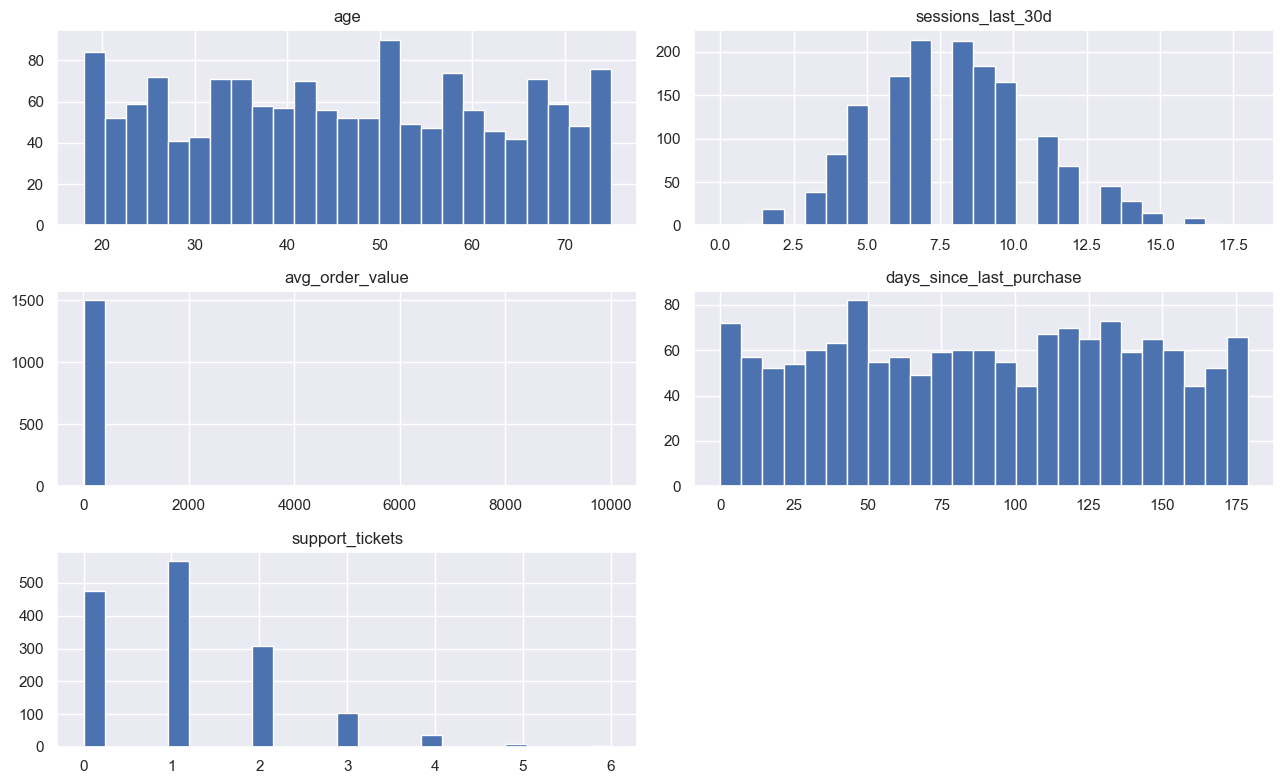

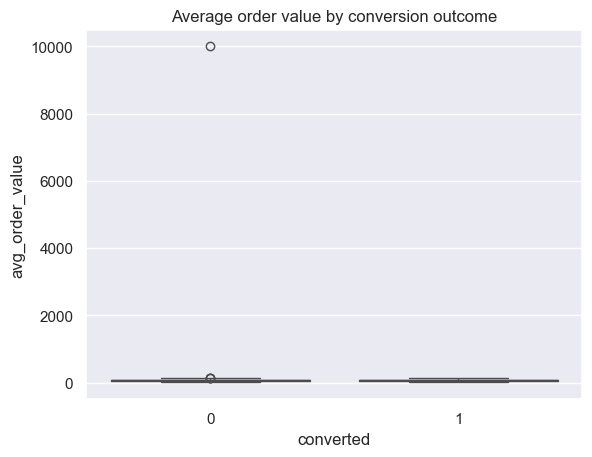

In [3]:
display(describe_numeric(df))
num_cols = ["age","sessions_last_30d","avg_order_value","days_since_last_purchase","support_tickets"]
df[num_cols].hist(figsize=(13, 8), bins=25)
plt.tight_layout()
plt.show()
sns.boxplot(data=df, x="converted", y="avg_order_value")
plt.title("Average order value by conversion outcome")
plt.show()

## 3. Categorical breakdowns

,customers,conversion_rate,conversion_rate_pct
device,,,
Mobile,845,0.205917,20.59
Tablet,136,0.198529,19.85
Desktop,519,0.194605,19.46


,customers,conversion_rate,conversion_rate_pct
acquisition_channel,,,
Email,308,0.227273,22.73
Social,287,0.205575,20.56
Referral,331,0.199396,19.94
Organic,285,0.189474,18.95
Paid Search,289,0.183391,18.34


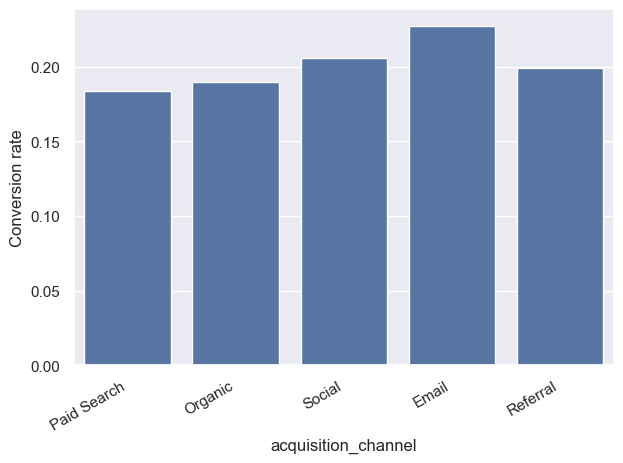

In [4]:
for col in ["device", "acquisition_channel"]:
    summary = df.groupby(col, dropna=False).agg(
        customers=("customer_id","count"),
        conversion_rate=("converted","mean")
    ).sort_values("conversion_rate", ascending=False)
    summary["conversion_rate_pct"] = (summary["conversion_rate"]*100).round(2)
    display(summary)
sns.barplot(data=df, x="acquisition_channel", y="converted", errorbar=None)
plt.xticks(rotation=30, ha="right")
plt.ylabel("Conversion rate")
plt.tight_layout()
plt.show()

## 4. Correlations and statistical tests
Mann–Whitney U compares ranks between two independent groups and does not require normally distributed outcomes. The p-value does not measure business importance.

In [5]:
display(df[num_cols + ["converted"]].corr(numeric_only=True))
converted = df.loc[df["converted"] == 1, "sessions_last_30d"]
not_converted = df.loc[df["converted"] == 0, "sessions_last_30d"]
display(mann_whitney_test(converted, not_converted))
# Chi-square test: is conversion independent of device category?
contingency = pd.crosstab(df["device"], df["converted"])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
print({"chi2": chi2, "p_value": p, "degrees_of_freedom": dof})
display(contingency)

,age,sessions_last_30d,avg_order_value,days_since_last_purchase,support_tickets,converted
age,1.000000,0.010663,-0.034068,-0.000095,-0.029358,-0.030984
sessions_last_30d,0.010663,1.000000,0.013623,-0.004558,-0.032694,0.114750
avg_order_value,-0.034068,0.013623,1.000000,-0.032876,-0.027998,-0.015730
days_since_last_purchase,-0.000095,-0.004558,-0.032876,1.000000,0.027536,-0.247725
support_tickets,-0.029358,-0.032694,-0.027998,0.027536,1.000000,-0.081403
converted,-0.030984,0.114750,-0.015730,-0.247725,-0.081403,1.000000


{'n_a': 302,
 'n_b': 1198,
 'u_statistic': 209507.5,
 'p_value': 1.8843033357863654e-05}

{'chi2': 0.26318215610321594, 'p_value': 0.8766994234261513, 'degrees_of_freedom': 2}


converted,0,1
device,,
Desktop,418,101
Mobile,671,174
Tablet,109,27


## 5. Segment-level analysis

,customers,conversion_rate,mean_sessions,mean_aov
recency_segment,,,,
0–7 days,72,0.430556,7.652778,71.391944
8–30 days,180,0.322222,7.866667,129.855000
31–90 days,509,0.253438,8.306483,74.556326
91–180 days,739,0.113667,7.944520,75.482206


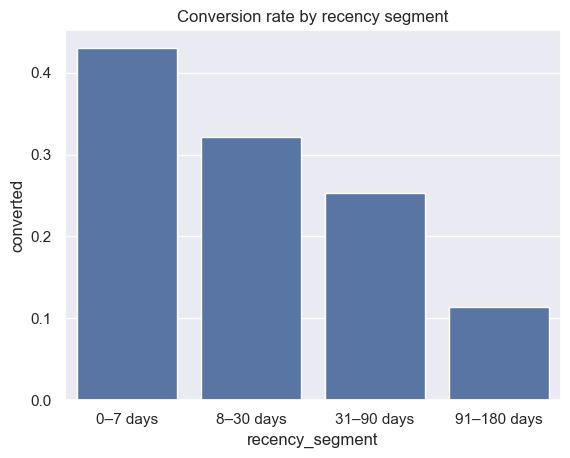

In [6]:
df["recency_segment"] = pd.cut(
    df["days_since_last_purchase"], bins=[-1, 7, 30, 90, 180],
    labels=["0–7 days","8–30 days","31–90 days","91–180 days"]
)
display(df.groupby("recency_segment", observed=False).agg(
    customers=("customer_id","count"),
    conversion_rate=("converted","mean"),
    mean_sessions=("sessions_last_30d","mean"),
    mean_aov=("avg_order_value","mean")
))
sns.barplot(data=df, x="recency_segment", y="converted", errorbar=None)
plt.title("Conversion rate by recency segment")
plt.show()

## 6. Automated profile

In [7]:
report_path = PROJECT_ROOT / "reports/customer_behavior_profile.html"
create_profile(df, "Customer Behavior EDA Profile", report_path)
print("Saved:", report_path)

Saved: E:\Linkific\Day 7\reports\customer_behavior_profile.html


C:\Users\niran\AppData\Local\Temp\ipykernel_32928\2964157930.py:2: RuntimeWarning: ydata-profiling is not installed in this Python environment; writing a basic HTML summary instead.
  create_profile(df, "Customer Behavior EDA Profile", report_path)


## Findings template
Report associations, sample sizes, uncertainty, and potential confounders. Avoid treating observational segments as causal explanations.